# IS 4487 Assignment 7: Data Transformation with Airbnb Listings

In this assignment, you will:
- Load the Airbnb dataset you cleaned in Assignment 6
- Apply data transformation techniques like scaling, binning, encoding, and feature creation
- Make the dataset easier to use for tasks like pricing analysis, guest segmentation, or listing recommendations
- Practice writing up your analysis clearly so a business audience — like a host, marketing manager, or city partner — could understand it

## Why This Matters

Airbnb analysts, hosts, and city partners rely on clean and well-structured data to make smart decisions. Whether they’re adjusting prices, identifying high-performing listings, or designing better guest experiences, they need data that’s transformed, organized, and ready for use.

This assignment helps you practice that kind of real-world thinking: taking messy real data and getting it ready for action.

<a href="https://colab.research.google.com/github/Stan-Pugsley/is_4487_base/blob/main/Assignments/assignment_07_data_transformation.ipynb" target="_parent">
  <img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/>
</a>



## Dataset Description

The dataset you'll be using is a **detailed Airbnb listing file**, available from [Inside Airbnb](https://insideairbnb.com/get-the-data/).

Each row represents one property listing. The columns include:

- **Host attributes** (e.g., host ID, host name, host response time)
- **Listing details** (e.g., price, room type, minimum nights, availability)
- **Location data** (e.g., neighborhood, latitude/longitude)
- **Property characteristics** (e.g., number of bedrooms, amenities, accommodates)
- **Calendar/booking variables** (e.g., last review date, number of reviews)

The schema is consistent across cities, so you can expect similar columns regardless of the location you choose.

Choose a City & Upload Your Dataset
📥 Follow these steps:

Go to: https://insideairbnb.com/get-the-data/
Choose a city you’re interested in.
Download the file named: listings.csv.gz under that city.
In your notebook:
Open the left sidebar
Click the folder icon 📁
Click the upload icon ⬆️ and choose your listings.csv.gz file
Use the file path /content/listings.csv.gz when loading your data.
Import standard libraries (pandas, numpy, seaborn, matplotlib)

## 1. Setup and Load Your Data

You'll be working with the `cleaned_airbnb_data_6.csv` file you exported from Assignment 6. (Note: If you had significant errors with assignment 6, you can use the file named "airbnb_listings.csv" in the DataSets folder on GitHub as a backup starting point.)

### Do the following:
In Google Colab:
- Click the folder icon on the left sidebar
- Use the upload button to add your CSV file to the session
- Then use the code block below to read it into your notebook

Before getting started, make sure you import the libraries you'll need for this assignment:
- `pandas`, `numpy` for data manipulation
- `matplotlib.pyplot`, `seaborn` for visualizations


cleaned_airbnb_data_6.csv not found in workspace. Loading backup file from GitHub...
Data loaded successfully! Shape: (459, 77)


,id,listing_url,scrape_id,last_scraped,source,name,description,neighborhood_overview,host_url,host_name,...,review_scores_communication,review_scores_location,review_scores_value,license,instant_bookable,calculated_host_listings_count,calculated_host_listings_count_entire_homes,calculated_host_listings_count_private_rooms,calculated_host_listings_count_shared_rooms,reviews_per_month
0,2992450,https://www.airbnb.com/rooms/2992450,20250804133828,2025-08-04,city scrape,Luxury 2 bedroom apartment,The apartment is located in a quiet neighborho...,NaN,https://www.airbnb.com/users/show/4621559,Kenneth,...,4.56,3.22,3.67,NaN,0,1,1,0,0,0.07
1,3820211,https://www.airbnb.com/rooms/3820211,20250804133828,2025-08-04,city scrape,Funky Urban Gem: Prime Central Location - Park...,Step into the charming and comfy 1BR/1BA apart...,Overview<br /><br />The lovely apartment is lo...,https://www.airbnb.com/users/show/19648678,Terra,...,4.81,4.81,4.77,NaN,0,4,4,0,0,2.32
2,5651579,https://www.airbnb.com/rooms/5651579,20250804133828,2025-08-04,city scrape,Large studio apt by Capital Center & ESP@,"Spacious studio with hardwood floors, fully eq...",The neighborhood is very eclectic. We have a v...,https://www.airbnb.com/users/show/29288920,Gregg,...,4.88,4.76,4.64,NaN,0,2,1,1,0,2.97
3,6623339,https://www.airbnb.com/rooms/6623339,20250804133828,2025-08-04,city scrape,Bright & Cozy City Stay · Top Location + Parking!,Step into the charming and comfy 1BR/1BA apart...,Overview<br /><br />The lovely apartment is lo...,https://www.airbnb.com/users/show/19648678,Terra,...,4.70,4.80,4.72,NaN,0,4,4,0,0,2.68
4,9005989,https://www.airbnb.com/rooms/9005989,20250804133828,2025-08-04,city scrape,"Studio in The heart of Center SQ, in Albany NY",(21 years of age or older ONLY) NON- SMOKING.....,"There are many shops, restaurants, bars, museu...",https://www.airbnb.com/users/show/17766924,Sugey,...,4.93,4.87,4.77,NaN,0,1,1,0,0,5.67


## 2. Check for Skew in a Numeric Column

### Business framing:  

Airbnb listings can have a wide range of values for things like price, availability, or reviews. These kinds of distributions can be hard to visualize, summarize, or model.

### Do the following:
Choose one **numeric column** that appears skewed and do the following:
- Plot a histogram
- Apply a transformation (e.g., log or other method)
- Plot again to compare

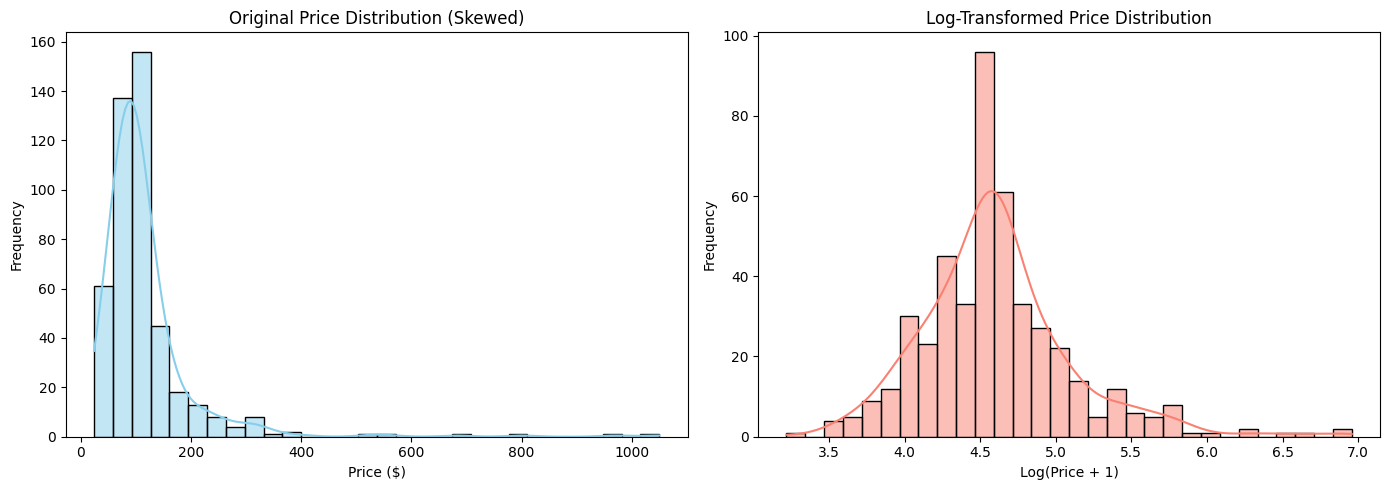

### Reflection:
1. What column did you examine?
2. What transformation did you try, and why?
3. How did the transformed version help make the data more usable for analysis or stakeholder review?

### ✍️ Your Response: 🔧
1. I examined the price column because Airbnb listings have a wide range of prices, and some are much more expensive than others.

2. I used a log transformation to reduce the impact of extremely high prices. The original data was heavily skewed to the right, and the transformation helped make the distribution more balanced.


3. The transformed data is easier to analyze because the extreme prices have less influence on the distribution. This helps Airbnb analysts and hosts better understand typical listing prices and compare properties more effectively.

## 3. Scale Two Numeric Columns

### Business framing:

If an analyst wanted to compare listing price to number of nights required, or create a model that weighs both, those values need to be on a similar scale.

### Do the following:
- Pick two numeric columns with different value ranges (e.g. one column may have a min of 0 and a max of 255; another column may have a min of 100 and a max of 400)
- Use Min-Max scaling on one column (the range should be “shrinked” down to just 0-1)
- Use Z-score Normalization (aka standardization) on the other column.
- Add 2 new columns to the dataset. These 2 new columns should be the ones you just created.

In [4]:

from sklearn.preprocessing import MinMaxScaler, StandardScaler

# Min-Max scale price
minmax = MinMaxScaler()
df['price_scaled'] = minmax.fit_transform(df[['price']])

# Z-score scale minimum nights
standard = StandardScaler()
df['minimum_nights_scaled'] = standard.fit_transform(df[['minimum_nights']])

# Compare original and scaled values
df[['price', 'price_scaled', 'minimum_nights', 'minimum_nights_scaled']].describe()



,price,price_scaled,minimum_nights,minimum_nights_scaled
count,459.000000,459.000000,459.000000,4.590000e+02
mean,116.104575,0.089771,6.732026,1.548023e-17
std,96.346706,0.093905,19.922231,1.001091e+00
min,24.000000,0.000000,1.000000,-2.880340e-01
25%,73.000000,0.047758,1.000000,-2.880340e-01
50%,95.000000,0.069201,2.000000,-2.377841e-01
75%,121.000000,0.094542,3.000000,-1.875341e-01
max,1050.000000,1.000000,365.000000,1.800295e+01



### Reflection:
1. What two columns did you scale, and which methods did you use?
2. When might these scaled values be more useful than the originals?
3. Who at Airbnb might benefit from this transformation and why?

### ✍️ Your Response: 🔧
1. I scaled the price column using Min-Max scaling and the minimum_nights column using Z-score standardization. This helps make the values easier to compare.

2. These scaled values are more useful when comparing different Airbnb listings or building models. Since the original columns have different ranges, scaling helps prevent larger values from having too much influence.

3. Airbnb data analysts and pricing managers could benefit from this transformation. It helps them compare pricing and minimum stay requirements to better understand listing patterns and make informed business decisions.

## 4. Group a Numeric Column into Categories

### Business framing:  

Let’s say an Airbnb marketing team wants to segment listings by review activity. They don’t want exact numbers — they just want to know if a listing has “low,” “medium,” or “high” review volume.

### Do the following:

- Choose a numeric column that could be grouped (e.g., reviews, availability).
- You’ll want to group the values of this column into 3 or 4 bins
- Create a new column. The values of this column will be the labels: “Low”, “Medium”, and “High.” These labels should correspond to your bins.

review_volume_category
Medium    156
Low       155
High      148
Name: count, dtype: int64

Sample representation:


,number_of_reviews,review_volume_category
0,9,Medium
1,310,High
2,371,High
3,332,High
4,621,High
5,428,High
6,821,High
7,201,High
8,231,High
9,28,Medium


### Reflection:
1. What column did you group, and how many categories did you use?
2. Why might someone prefer this grouped view over raw numbers?
3. Who would this help at Airbnb, and how?

### ✍️ Your Response: 🔧
1. I grouped the number_of_reviews column into three categories: Low, Medium, and High. The groups had around the same number of listings.

2. Grouping the reviews makes it easier to compare listings without having to look at every individual number. It also helps identify which properties have more or less review activity.

3. This could help Airbnb marketing teams and hosts better understand listing performance. They could use these categories to identify listings with lower review activity and decide which properties might benefit from additional marketing or promotion.

## 5. Create Two New Business-Relevant Variables

### Business framing:  

Stakeholders often want to know things like: What’s the cost per night? Are listings geared toward long-term stays? These kinds of features aren’t always in the dataset — analysts create them.

### Do the following:

- Think of two new columns you can create using the data you already have.
  - One might be a ratio or interaction between columns (e.g., price ÷ nights).
  - The other might be a flag based on a condition (e.g., stays longer than 30 days).
- Add the new columns to your DataFrame.

   price  accommodates  cost_per_accommodate  minimum_nights  \
0   70.0             4                  17.5              28   
1  104.0             2                  52.0               2   
2   75.0             2                  37.5               2   
3  101.0             2                  50.5               2   
4  110.0             4                  27.5               1   
5   60.0             2                  30.0               1   
6   47.0             1                  47.0               1   
7  192.0            10                  19.2               1   
8   55.0             1                  55.0              15   
9   58.0             1                  58.0               5   

   is_long_term_stay  
0              False  
1              False  
2              False  
3              False  
4              False  
5              False  
6              False  
7              False  
8              False  
9              False  

Number of Long Term Stay listings: 28


### Reflection:
1. What two new columns did you create and why?
2. Who would use them (e.g., host, manager, or platform)?
3. How could they help someone make a better decision?

### ✍️ Your Response: 🔧
1. I created two new columns called cost_per_accommodate and is_long_term_stay. The first calculates the price per guest, while the second identifies listings that require a minimum stay of 30 nights or more.

2. Airbnb hosts, property managers, and the platform could use these columns to better understand their listings and compare different properties.

3. These features could help hosts make better pricing decisions and help guests find listings that fit their budget and stay requirements. They also make it easier to identify properties that are better suited for longer stays.



## 6. Encode a Categorical Column

### Business framing:  

Let’s say you’re helping the Airbnb data science team build a model to predict booking rates. Categorical columns like `room_type`, `neighbourhood`, or `cancellation_policy` can’t be used in models unless they’re converted to numbers.

### Do the following:
- Choose one categorical column from your dataset (e.g., room type or neighborhood group)
- Decide on an encoding method:
  - Use one-hot encoding for nominal (unordered) categories
  - Use ordinal encoding (a ranking) only if the categories have a clear order
- Apply the encoding using `pandas` or another tool
- Add the new encoded column(s) to your DataFrame

Original room types: ['Entire home/apt' 'Private room']

Newly added encoded columns:
   room_type_Entire home/apt  room_type_Private room
0                          1                       0
1                          1                       0
2                          1                       0
3                          1                       0
4                          1                       0


### Reflection:
1. What column did you encode and why?
2. What encoding method did you use?
3. How could this transformation help a pricing model, dashboard, or business report?

### ✍️ Your Response: 🔧
1. I encoded the room_type column because Airbnb listings have different types of rooms, and this information could be useful when comparing properties and predicting prices.
2. I used one-hot encoding to turn the room types into numerical values. This created two new columns that use 0s and 1s to identify each room type.
3. This transformation could help Airbnb analysts compare prices between entire homes and private rooms. It also makes the data easier to use in pricing models and dashboards to identify patterns and make better business decisions.

## 7. Export Cleaned Data

Before wrapping up, export your cleaned Airbnb dataset to a CSV file. You'll need this file for **Assignment 11**, where you'll use the data in a regression model.

### Do the following:
Make sure your data has:
- Cleaned and consistent column values
- Proper data types for each column
- Any unnecessary columns removed

This file should be the version of your dataset that you’d feel confident sharing with a teammate or using for deeper analysis.



```
# Explanation:
# - "cleaned_airbnb_data_7.csv" is the name of the file that will be saved
# - index=False prevents pandas from writing row numbers into the CSV
# - The file will be saved to your working directory (in Colab, you'll need to download it manually. Once you see the data in your files tab, just click on the three dots, then click “download”)
# - YOU MAY NEED TO PRESS “RUN” MULTIPLE TIMES IN ORDER FOR IT TO SHOW UP
# - FOR SOME DEVICES, IT MAY TAKE A FEW MINUTES BEFORE YOUR FILE SHOWS UP

```

Your dataset has been exported successfully to 'cleaned_airbnb_data_7.csv'!


## 8. Reflection

You’ve applied the same kinds of transformation techniques used in real Airbnb analytics projects — from pricing engines to host tools to tourism dashboards.

Now step back and reflect.

### Reflection:
1. What transformation step felt most important or interesting?
2. Which of your changes would be most useful to a host, analyst, or city planner?
3. If you were going to build a tool or dashboard, what would you do next with this data?
4. How does this relate to your customized learning outcome you created in canvas?



### ✍️ Your Response: 🔧

1. I think creating new features was the most interesting part of this assignment. It showed me how we can take existing data and turn it into new information that can be useful for making business decisions.

2.  I think the cost per guest and long-term stay features would be most useful for Airbnb hosts and analysts. These help compare property prices and identify listings that are better suited for longer stays.

3. If I were building a dashboard, I would include average listing prices, review activity, and room types. This would make it easier to compare properties and identify patterns that could help hosts improve their listings.
4. This assignment connects to my learning goal of using data analytics to make better business decisions. It helped me practice organizing and transforming data into information that can be used to understand trends and make informed decisions.



## Submission Instructions
✅ Checklist:
- All code cells run without error
- All markdown responses are complete
- Submit on Canvas as instructed

In [ ]:
!jupyter nbconvert --to html "assignment_07_data_transformation.ipynb"